# Impact Scenarios for the FFS Transition Strategy

This notebook turns the proposed solutions into **illustrative, measurable scenarios**. The rates are editable planning assumptions, not IEHP targets or predicted outcomes.

1. **Warm handoffs:** estimated member connections at low, medium, and high completion assumptions.
2. **Provider verification:** the modeled provider benchmark shown across the 10 priority ZIPs.
3. **Financial response:** modeled annual cost-removal or offset thresholds under low, middle, and high assumptions.

Estimated member counts are not observed transitions. Provider benchmarks are not verified shortages or hiring needs. Scenario results are not promised impacts.



In [38]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from matplotlib import font_manager

root = Path.cwd()
OUTPUTS = root / "analysis_outputs"
ACCESS = OUTPUTS / "access"
FINANCIAL = OUTPUTS / "financial"
export_dir = OUTPUTS / "slide_exports"
font_dir = export_dir / "fonts"

for font_file in (font_dir / "Inter-Regular.ttf", font_dir / "Inter-Bold.ttf"):
    if not font_file.is_file():
        raise FileNotFoundError(f"Bundled Inter font not found: {font_file}")
    font_manager.fontManager.addfont(str(font_file))

cpp_green, cpp_gold = "#005030", "#FFB81C"
ink, grid = "#111111", "#E1E1E1"
plt.rcParams.update({
    "font.family": "Inter", "font.size": 15, "text.color": ink,
    "axes.labelcolor": ink, "xtick.color": ink, "ytick.color": ink,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": grid, "axes.axisbelow": True, "axes.grid": True,
    "grid.color": grid, "grid.linewidth": 0.8, "svg.fonttype": "none",
})
export_dir.mkdir(parents=True, exist_ok=True)

required_files = [
    ACCESS / "scale_scenarios.csv",
    ACCESS / "provider_conversion_whatif.csv",
    FINANCIAL / "trigger_sizing.csv",
]
missing_files = [str(path) for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError("Required analysis inputs are missing: " + ", ".join(missing_files))

scale = pd.read_csv(ACCESS / "scale_scenarios.csv")
provider = pd.read_csv(ACCESS / "provider_conversion_whatif.csv", dtype={"ZIP": str})
financial = pd.read_csv(FINANCIAL / "trigger_sizing.csv")
print(f"Loaded {len(provider):,} provider-planning rows.")
print("Slide exports will be saved to:", export_dir.relative_to(root))



Loaded 10 provider-planning rows.
Slide exports will be saved to: analysis_outputs\slide_exports


## 1. Warm handoffs: member connections

The analysis estimates **8,136 transitioning members in the 10 highest-priority ZIPs** under IEHP's 119,600-member estimate. The rates below are hypothetical completion rates for a successful warm handoff, defined here as a prioritized member having a verified FFS provider and appointment within 30 days. They are not measured IEHP performance or recommended targets.

In [39]:
# Editable planning assumptions; replace with IEHP-approved scenarios.
handoff_rates = {
    "Low (50% assumed)": 0.50,
    "Planning (70% assumed)": 0.70,
    "High (90% assumed)": 0.90,
}

estimate_row = scale.loc[scale.iloc[:, 0].eq("IEHP estimate (Q&A)")]
if len(estimate_row) != 1:
    raise ValueError("Expected exactly one 'IEHP estimate (Q&A)' row in scale_scenarios.csv")

priority_members = int(estimate_row.iloc[0]["Top-10 ZIP total"])
handoff_scenarios = pd.DataFrame(
    [
        {
            "Scenario (assumption)": label,
            "Assumed successful handoff rate": rate,
            "Estimated members connected": round(priority_members * rate),
            "Estimated members not yet connected": priority_members - round(priority_members * rate),
        }
        for label, rate in handoff_rates.items()
    ]
)

print(f"Estimated transition members in top 10 ZIPs: {priority_members:,} (subset of the 119,600 planning estimate)")
display(handoff_scenarios.style.format({"Assumed successful handoff rate": "{:.0%}"}))



Estimated transition members in top 10 ZIPs: 8,136 (subset of the 119,600 planning estimate)


,Scenario (assumption),Assumed successful handoff rate,Estimated members connected,Estimated members not yet connected
0,Low (50% assumed),50%,4068,4068
1,Planning (70% assumed),70%,5695,2441
2,High (90% assumed),90%,7322,814


PNG: impact_warm_handoff_CPP_Inter.png
SVG: impact_warm_handoff_CPP_Inter.svg


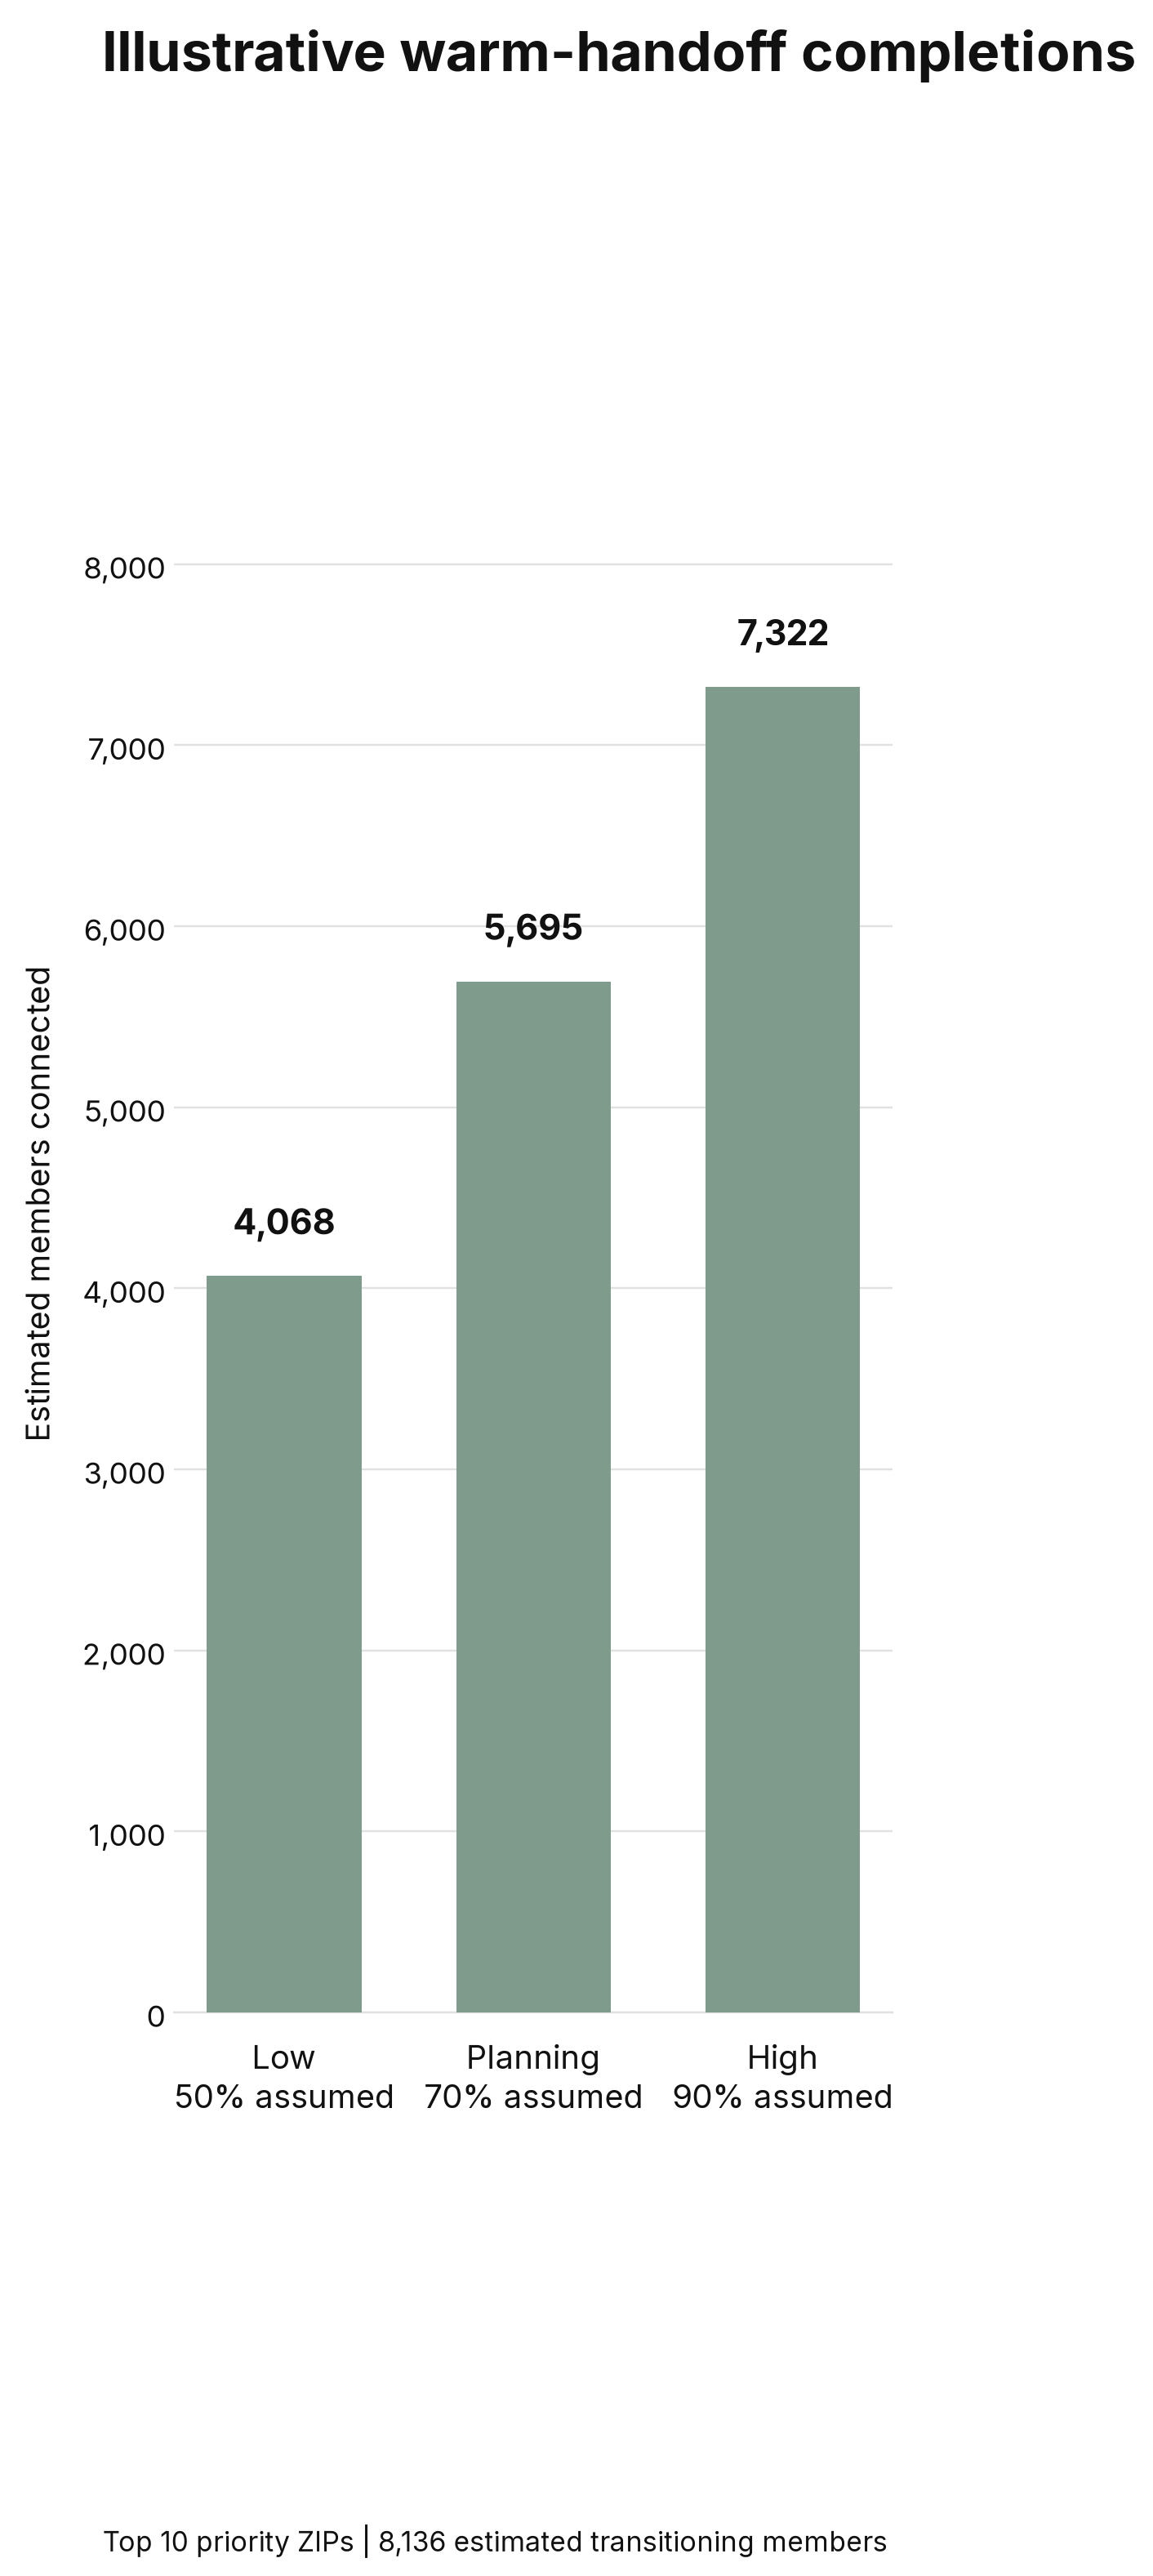

In [45]:
fig, ax = plt.subplots(figsize=(5, 15))
labels = ["Low\n50% assumed", "Planning\n70% assumed", "High\n90% assumed"]
values = handoff_scenarios["Estimated members connected"].tolist()
muted_green = "#7F9B8C"
bars = ax.bar(labels, values, width=0.62, color=muted_green, zorder=3)
ax.tick_params(axis="x", length=0, labelsize=13, pad=10)
ax.tick_params(axis="y", length=0, labelsize=12)
ax.set_ylabel("Estimated members connected", fontsize=13, labelpad=10)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, max(values) * 1.22)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + max(values) * 0.025, f"{value:,}", ha="center", va="bottom", fontsize=14, fontweight="bold", color=ink)
fig.suptitle("Illustrative warm-handoff completions", x=0.08, y=0.98, ha="left", fontsize=22, fontweight="bold", color=ink)
fig.text(0.08, 0.04, "Top 10 priority ZIPs | 8,136 estimated transitioning members", fontsize=11, color=ink)
fig.subplots_adjust(left=0.16, right=0.96, top=0.84, bottom=0.24)
for extension in ("png", "svg"):
    fig.savefig(export_dir / f"impact_warm_handoff_CPP_Inter.{extension}", dpi=220, bbox_inches="tight")
plt.close(fig)
print("PNG: impact_warm_handoff_CPP_Inter.png")
print("SVG: impact_warm_handoff_CPP_Inter.svg")
display(Image(filename=str(export_dir / "impact_warm_handoff_CPP_Inter.png")))




## 2. Provider verification: benchmark across the top 10 ZIPs

The chart shows the modeled provider count for each of the 10 ZIPs in the provider-conversion analysis. Counts represent the estimated number of additional listed providers corresponding to a team-defined regional median benchmark. They are **not verified shortages, confirmed accepting providers, or hiring targets**. Winchester, San Jacinto, and Lake Elsinore are highlighted because they remain high-priority across tested variants.


In [41]:
benchmark_column = "Providers to reach median TPP"
if benchmark_column not in provider.columns:
    raise KeyError(f"Expected column not found: {benchmark_column}")

provider_top10 = provider.head(10).copy()
if len(provider_top10) != 10:
    raise ValueError(f"Expected 10 ZIP rows, found {len(provider_top10)}")
provider_top10[benchmark_column] = provider_top10[benchmark_column].astype(int)
highlighted_zips = {"92596", "92582", "92532"}
provider_top10["ZIP label"] = provider_top10["City"].str.title() + " (" + provider_top10["ZIP"] + ")"
provider_top10["Highlight"] = provider_top10["ZIP"].isin(highlighted_zips)

top10_benchmark = int(provider_top10[benchmark_column].sum())
print(f"Provider benchmark across the 10 ZIPs: {top10_benchmark} (modeled, not verified need)")
display(provider_top10[["ZIP label", "Est_Transition_A", "PCPs", benchmark_column]])


Provider benchmark across the 10 ZIPs: 118 (modeled, not verified need)


,ZIP label,Est_Transition_A,PCPs,Providers to reach median TPP
0,Desert Hot Springs (92240),1597.0,0,23
1,Moreno Valley (92551),1029.0,0,15
2,Eastvale (92880),926.0,0,13
3,Thermal (92274),835.0,0,12
4,Winchester (92596),676.0,0,10
5,San Jacinto (92582),670.0,0,10
6,Hesperia (92344),651.0,0,10
7,Mecca (92254),640.0,0,9
8,Lake Elsinore (92532),566.0,0,8
9,Indio (92203),545.0,0,8


PNG: impact_provider_capacity_CPP_Inter.png
SVG: impact_provider_capacity_CPP_Inter.svg


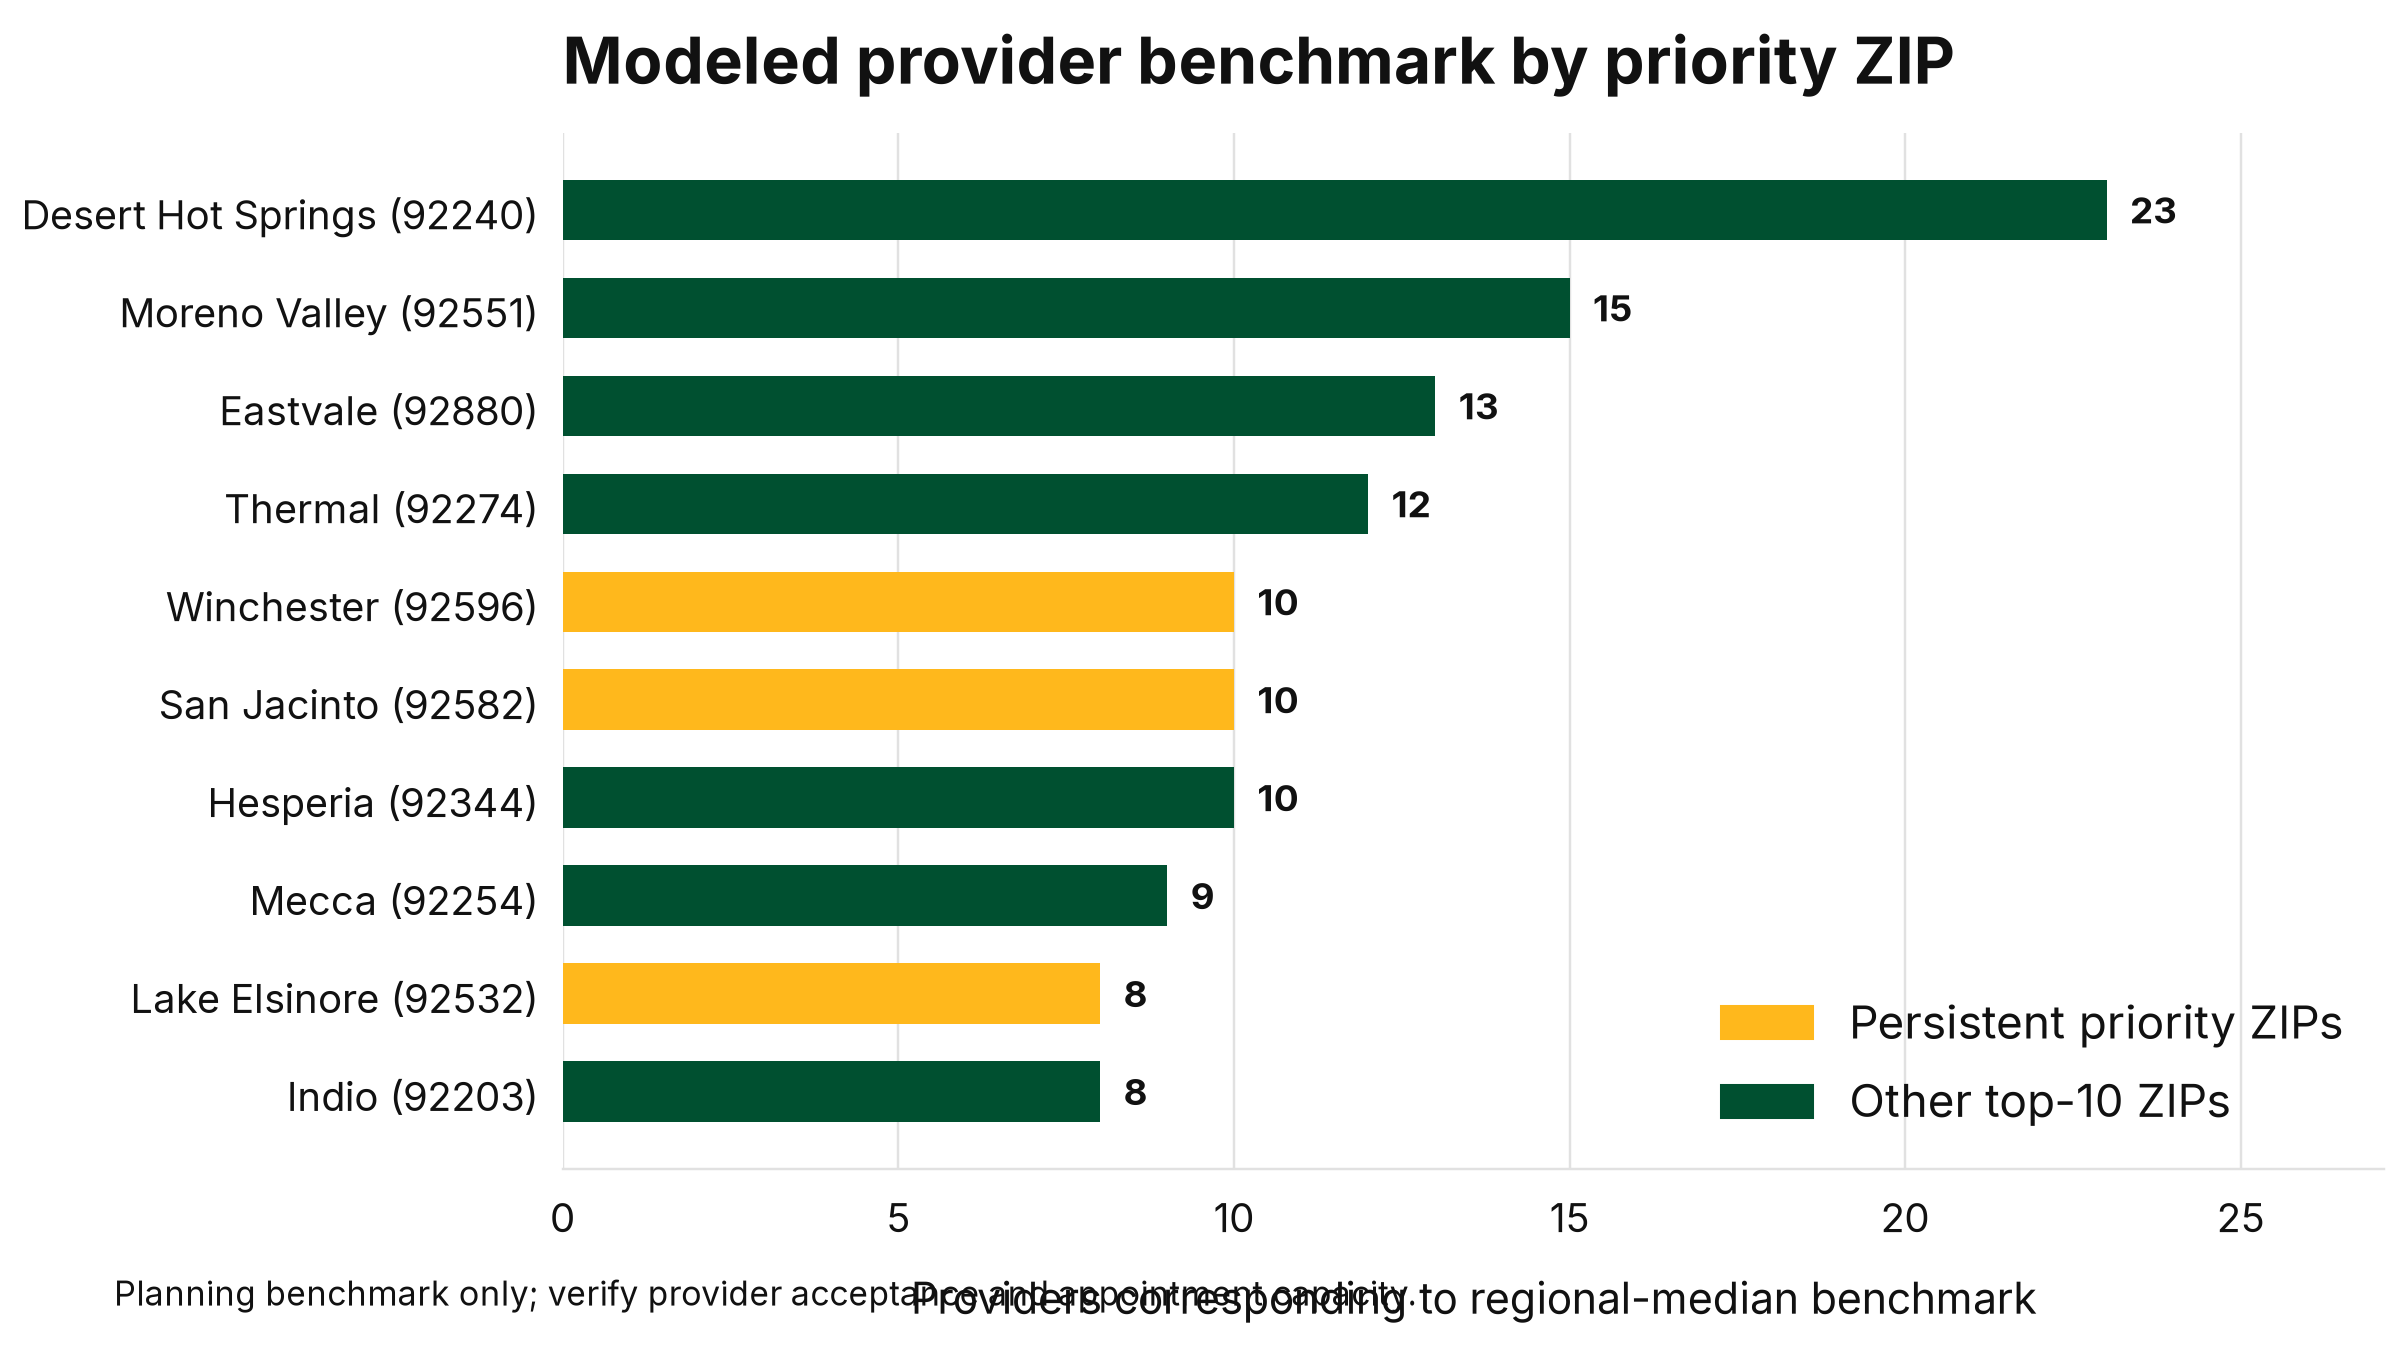

In [42]:
fig, ax = plt.subplots(figsize=(12, 6.2))
provider_top10_plot = provider_top10.iloc[::-1]
bar_colors = [cpp_gold if highlighted else cpp_green for highlighted in provider_top10_plot["Highlight"]]
bars = ax.barh(provider_top10_plot["ZIP label"], provider_top10_plot[benchmark_column], color=bar_colors, height=0.62, zorder=3)
ax.set_title("Modeled provider benchmark by priority ZIP", loc="left", fontsize=21, fontweight="bold", pad=16, color=ink)
ax.set_xlabel("Providers corresponding to regional-median benchmark", fontsize=14, labelpad=10)
ax.set_ylabel("")
ax.tick_params(axis="both", length=0, labelsize=13, pad=8)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, provider_top10[benchmark_column].max() * 1.18)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
for bar, value in zip(bars, provider_top10_plot[benchmark_column]):
    ax.text(value + 0.35, bar.get_y() + bar.get_height() / 2, f"{value}", va="center", fontsize=12, fontweight="bold", color=ink)
legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=cpp_gold, label="Persistent priority ZIPs"),
    plt.Rectangle((0, 0), 1, 1, color=cpp_green, label="Other top-10 ZIPs"),
]
ax.legend(handles=legend_handles, frameon=False, loc="lower right")
fig.text(0.08, 0.02, "Planning benchmark only; verify provider acceptance and appointment capacity.", fontsize=11, color=ink)
fig.subplots_adjust(left=0.25, right=0.94, top=0.88, bottom=0.12)
for extension in ("png", "svg"):
    fig.savefig(export_dir / f"impact_provider_capacity_CPP_Inter.{extension}", dpi=220, bbox_inches="tight")
plt.close(fig)
print("PNG: impact_provider_capacity_CPP_Inter.png")
print("SVG: impact_provider_capacity_CPP_Inter.svg")
display(Image(filename=str(export_dir / "impact_provider_capacity_CPP_Inter.png")))


## 3. Monitoring and financial response: mitigation thresholds

This returns to the original financial-response visual: the modeled annual fixed cost to remove or offset under low, middle, and high assumptions, at three per-member cost guardrails. It is not savings forecast from monitoring or a guaranteed result of the recommendations.


,Per-member cost guardrail,Low,Middle,High
0,Hold at today's level,$29.0M,$41.5M,$52.3M
1,Allow +5%,$15.6M,$28.7M,$40.0M
2,Allow +10%,$2.2M,$15.9M,$27.8M


PNG: impact_financial_response_CPP_Inter.png
SVG: impact_financial_response_CPP_Inter.svg


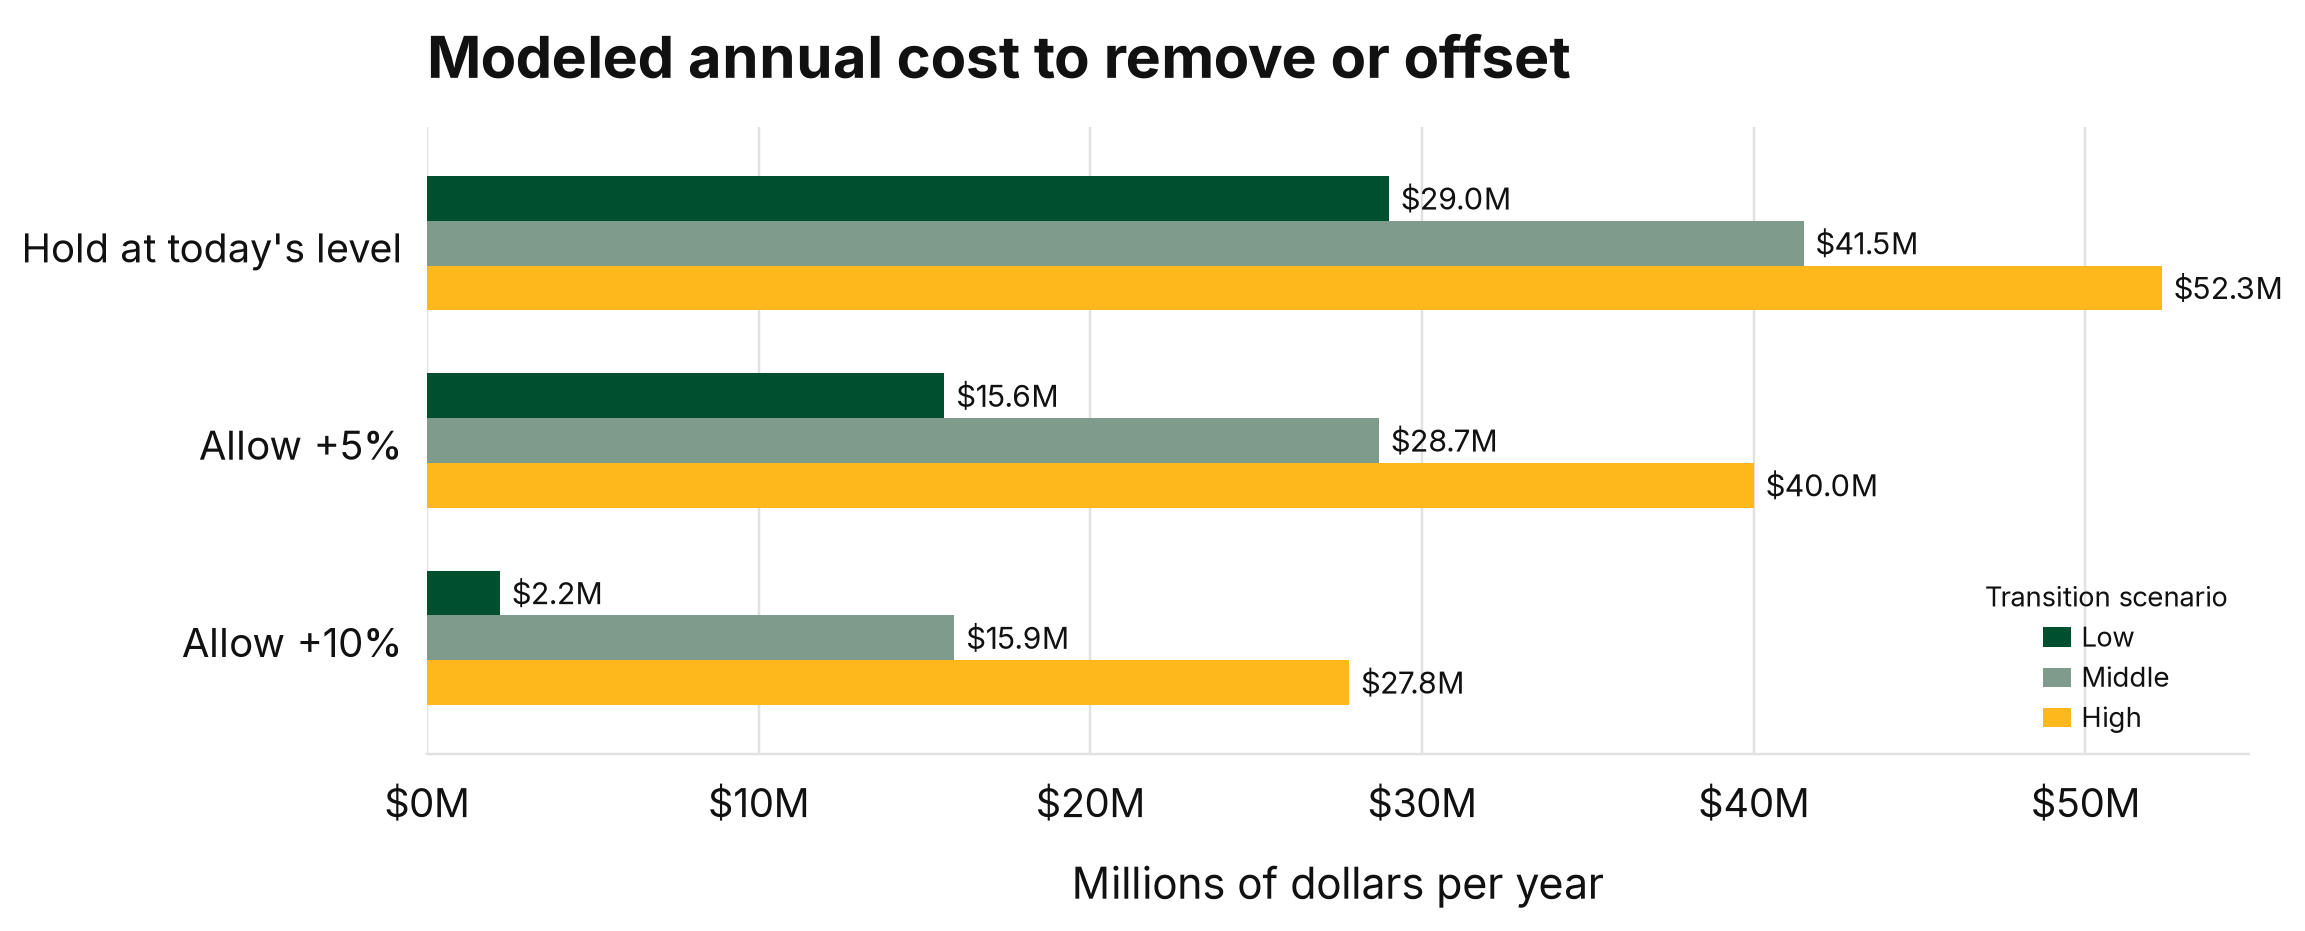

In [43]:
financial_scenarios = financial.rename(columns={financial.columns[0]: "Per-member cost guardrail"}).copy()
financial_plot = financial_scenarios.set_index("Per-member cost guardrail")[["Low", "Middle", "High"]].replace({r"[$M,]": ""}, regex=True).astype(float)
display(financial_scenarios)

fig, ax = plt.subplots(figsize=(12, 4.6))
financial_plot.plot.barh(ax=ax, color=[cpp_green, "#7F9B8C", cpp_gold], width=0.68, zorder=3)
ax.invert_yaxis()
ax.set_title("Modeled annual cost to remove or offset", loc="left", fontsize=19, fontweight="bold", pad=16, color=ink)
ax.set_xlabel("Millions of dollars per year", fontsize=14, labelpad=10)
ax.set_ylabel("")
ax.tick_params(axis="both", length=0, labelsize=13, pad=8)
ax.legend(title="Transition scenario", frameon=False, loc="lower right", fontsize=9, title_fontsize=9, handlelength=1.0, handletextpad=0.4, labelspacing=0.25, borderaxespad=0.35)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}M"))
for container in ax.containers:
    ax.bar_label(container, fmt="$%.1fM", padding=4, fontsize=10, color=ink)
fig.subplots_adjust(left=0.27, right=0.96, top=0.82, bottom=0.20)
for extension in ("png", "svg"):
    fig.savefig(export_dir / f"impact_financial_response_CPP_Inter.{extension}", dpi=220, bbox_inches="tight")
plt.close(fig)
print("PNG: impact_financial_response_CPP_Inter.png")
print("SVG: impact_financial_response_CPP_Inter.svg")
display(Image(filename=str(export_dir / "impact_financial_response_CPP_Inter.png")))


## Slide-ready interpretation

- **Warm handoffs:** Under the illustrative 50% / 70% / 90% completion assumptions, approximately **4,068 / 5,695 / 7,322** of the estimated 8,136 members in the top 10 ZIPs would have a verified provider and appointment within 30 days.
- **Provider verification:** Track outreach and confirmed FFS acceptance by ZIP against the **modeled benchmark shown for each of the 10 ZIPs**. Validate actual acceptance and appointment availability before treating any benchmark as a need.
- **Financial response:** Under the middle transition scenario, the model estimates **$41.5M**, **$28.7M**, or **$15.9M** per year to remove or offset to hold per-member fixed cost flat, within +5%, or within +10%, respectively. These are modeled thresholdsâ€”not savings from the plan.

The handoff rates are illustrative assumptions; provider numbers are planning benchmarks; and financial amounts are modeled thresholds. None are achieved or guaranteed impact.

